# Compression Shim Scan â€” Analysis (loading + R&R survival)

For a `CompressionShimScan` run: per (X, Y, Z1, Z2) compression-shim point,
**loading probability** and **release-and-recapture survival probability**
(a temperature probe â€” higher survival = colder atoms). Shows a 3D map (X, Y, Z1;
color = value) per Z2 value, and finds the 4D point with the **maximum survival**.

Thin driver over `analysis/analyze_compression_shim_scan.py`.

> **Run in the working-BLAS `python` env, NOT `artiq7_claude`.**

## 0. Setup

In [126]:
%load_ext autoreload
%autoreload 2

import sys, os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ANALYSIS_DIR = Path(r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\analysis")
for p in (str(ANALYSIS_DIR.parent), str(ANALYSIS_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from analyze_compression_shim_scan import (
    find_runs, load_run, aggregate, recommend, pick_case, print_summary,
    plot_maps_per_z2, plot_all_maps, plot_axis_gaussians, RESULTS_DIR,
)

%matplotlib inline
print("Setup complete")
print(f"Results dir: {RESULTS_DIR}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Setup complete
Results dir: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results


## 1. List runs

In [127]:
files = find_runs()
if not files:
    print(f"No CompressionShimScan .h5 under {RESULTS_DIR}")
for fp in files:
    print(os.path.basename(fp))

000001592-CompressionShimScan.h5
000001595-CompressionShimScan.h5
000001760-CompressionShimScan.h5
000001766-CompressionShimScan.h5
000001769-CompressionShimScan.h5
000001772-CompressionShimScan.h5
000001775-CompressionShimScan.h5
000001778-CompressionShimScan.h5


## 2. Load & summarize

`MIN_LOAD_PROB` / `MIN_LOADS` restrict which points are eligible when picking the
maximum-survival optimum (so a point that rarely loads can't win on a noisy
survival number).

In [128]:
########################################
RID           = None    # int RID, or None for latest
MIN_LOAD_PROB = 0.9      # ignore points with loading prob below this
MIN_LOADS     = 10       # ignore points with fewer loaded trials than this
########################################

files = find_runs()
if RID is not None:
    path = [f for f in files if os.path.basename(f).split('-')[0] == f"{RID:09d}"][-1]
else:
    path = files[-1]; print("(latest run)")

d = load_run(path)
agg = aggregate(d)
rec = print_summary(d, agg, min_load_prob=MIN_LOAD_PROB, min_loads=MIN_LOADS)

(latest run)
File: 000001778-CompressionShimScan.h5   RID=1778   t_release = 100.0 us
  total trials: 16000   grid points: 160
  overall loading prob: 40.2%
  overall R&R survival (of loaded): 26.2%
  deterministic loading time (loaded trials): mean 292 ms, min 0, max 4051

=== RECOMMENDATION (require loading rate >= 90%) ===
  13 point(s) meet the >= 90% loading requirement.

  [BEST by LOADING TIME only (fastest)]
    shim_X_compression=0.300  shim_Y_compression=0.600  shim_Z1_compression=4.280  shim_Z2_compression=4.180
    loading=95%   survival=28.4%   load time=76 ms   (95/100 loaded)
    grades:  time=100/100   survival=72/100   both=172/200

  [BEST by SURVIVAL only (coldest)]
    shim_X_compression=0.300  shim_Y_compression=0.200  shim_Z1_compression=4.320  shim_Z2_compression=4.180
    loading=94%   survival=33.0%   load time=132 ms   (94/100 loaded)
    grades:  time=88/100   survival=100/100   both=188/200

  [BEST by BOTH (survival high + time low)]
    shim_X_compression=

## View angle for the 3D maps

Set elevation and azimuth (degrees) to rotate all 3D maps. Re-run the map
cells below after changing these. (matplotlib default: 30, -60)

In [ ]:
########################################
VIEW_ELEV = 30    # elevation angle (deg)
VIEW_AZIM = -60   # azimuth angle (deg)
########################################

## 3. Loading-probability 3D map (one per Z2)

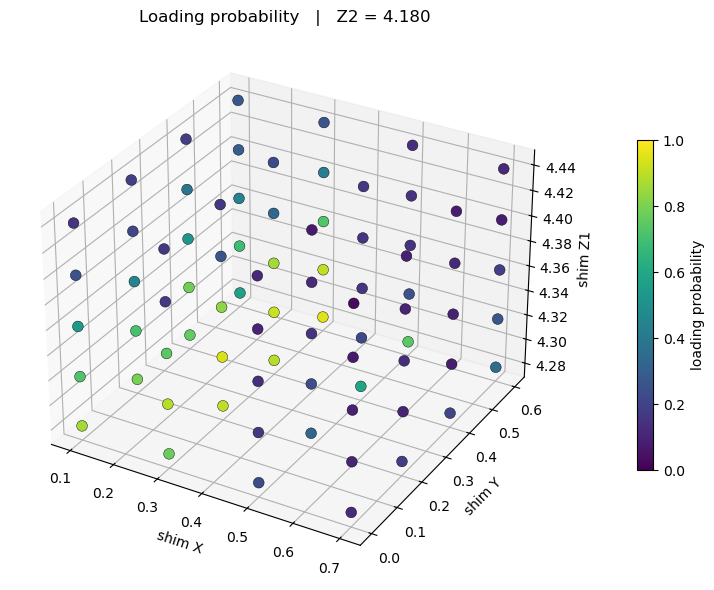

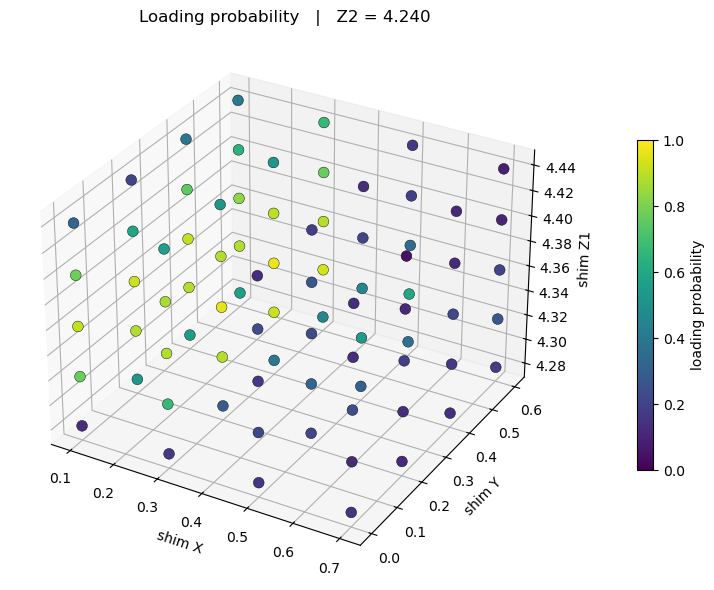

In [129]:
plot_maps_per_z2(agg, value="load_prob", elev=VIEW_ELEV, azim=VIEW_AZIM)

## 4. R&R survival 3D map (one per Z2)

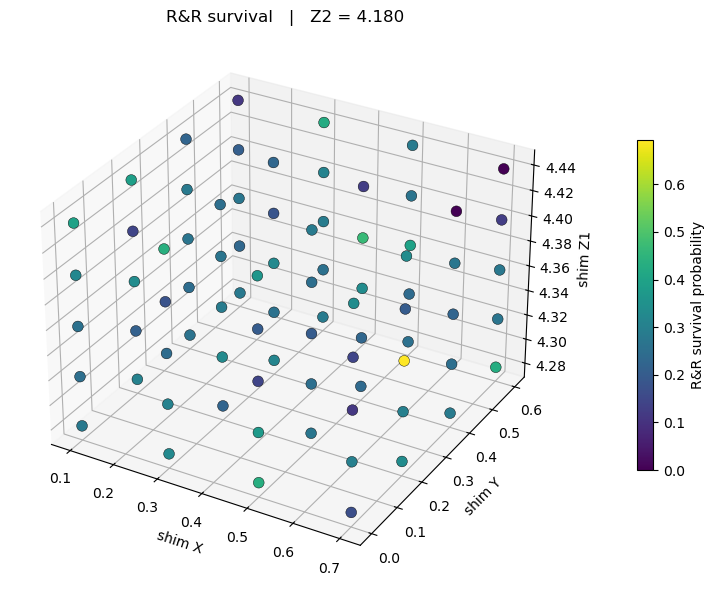

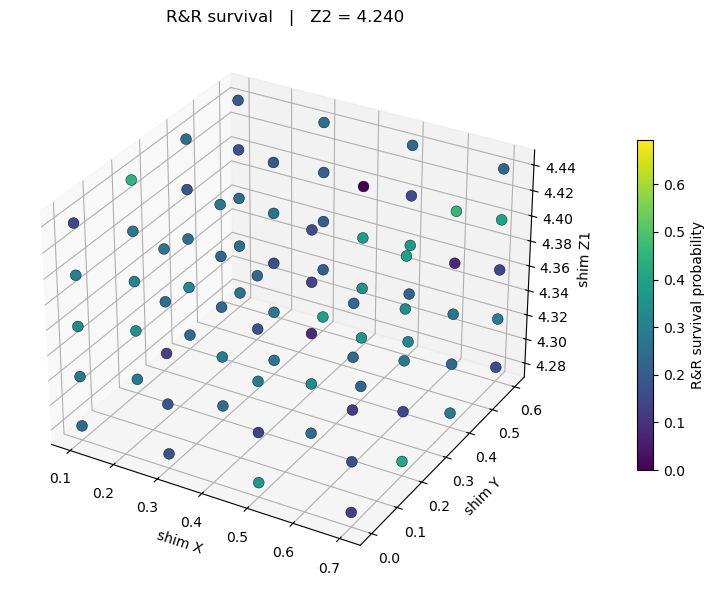

In [130]:
plot_maps_per_z2(agg, value="survival_prob", elev=VIEW_ELEV, azim=VIEW_AZIM)

## 4b. Deterministic loading-time 3D map (one per Z2)

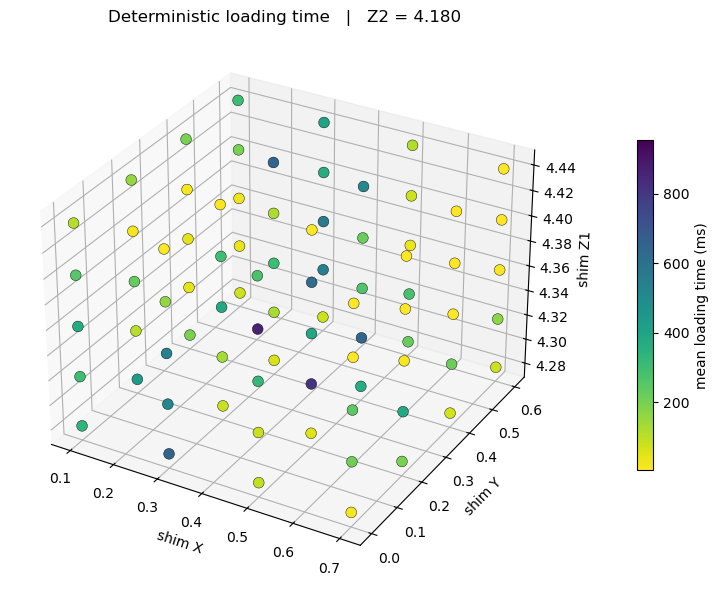

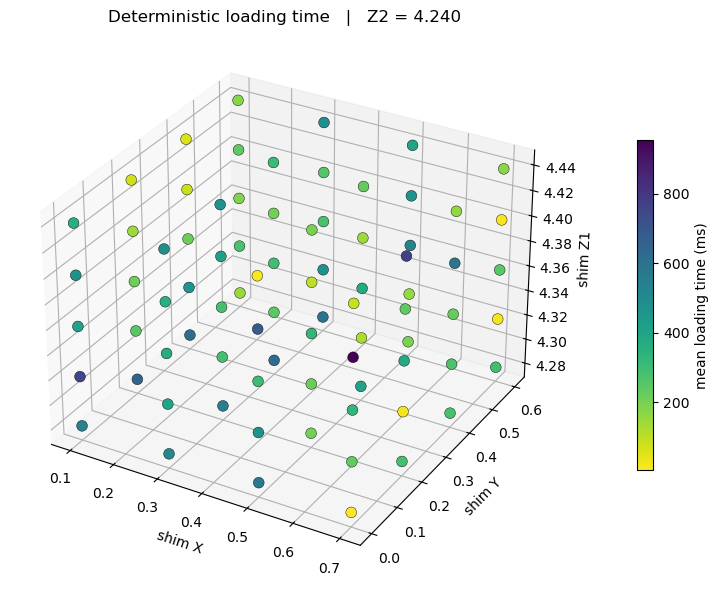

In [131]:
plot_maps_per_z2(agg, value="load_time", elev=VIEW_ELEV, azim=VIEW_AZIM)


## 5. Recommendations (>=90% loading gate)

Requires loading rate >= 90%; otherwise reports **every point is bad**. Gives the best by loading time only, by survival only, and by both.

In [132]:
def _p(tag, b):
    if not b:
        return
    print("")
    print(f"[{tag}]")
    print(f"  shim_X_compression  = {b['X']:.3f}")
    print(f"  shim_Y_compression  = {b['Y']:.3f}")
    print(f"  shim_Z1_compression = {b['Z1']:.3f}")
    print(f"  shim_Z2_compression = {b['Z2']:.3f}")
    print(f"  loading={b['load_prob']*100:.0f}%  survival={b['survival_prob']*100:.1f}%  load_time={b['load_time']*1e3:.0f} ms")

thr = rec["min_load_prob"] * 100
if not rec["qualified"]:
    print(f"EVERY POINT IS BAD - no point reaches the >= {thr:.0f}% loading requirement.")
else:
    print(f"{rec['n_qualified']} point(s) meet the >= {thr:.0f}% loading gate.")
    _p("BEST by loading time only (fastest)", rec["best_time"])
    _p("BEST by survival only (coldest)", rec["best_survival"])
    _p("BEST by BOTH", rec["best_both"])


13 point(s) meet the >= 90% loading gate.

[BEST by loading time only (fastest)]
  shim_X_compression  = 0.300
  shim_Y_compression  = 0.600
  shim_Z1_compression = 4.280
  shim_Z2_compression = 4.180
  loading=95%  survival=28.4%  load_time=76 ms

[BEST by survival only (coldest)]
  shim_X_compression  = 0.300
  shim_Y_compression  = 0.200
  shim_Z1_compression = 4.320
  shim_Z2_compression = 4.180
  loading=94%  survival=33.0%  load_time=132 ms

[BEST by BOTH]
  shim_X_compression  = 0.300
  shim_Y_compression  = 0.200
  shim_Z1_compression = 4.320
  shim_Z2_compression = 4.180
  loading=94%  survival=33.0%  load_time=132 ms


## 6. Case selection + Gaussian 1D cuts

Pick a `CASE`: **1** = fastest (loading time), **2** = best R&R survival, **3** = both.
It brings that case's scan values and plots loading time & R&R survival vs each shim
axis (cut through the optimum), each with a Gaussian fit.

CASE 1 chosen scan values:
  shim_X_compression  = 0.300
  shim_Y_compression  = 0.400
  shim_Z1_compression = 4.280
  shim_Z2_compression = 4.200
  grades: time=100/100  survival=100/100  both=200/200


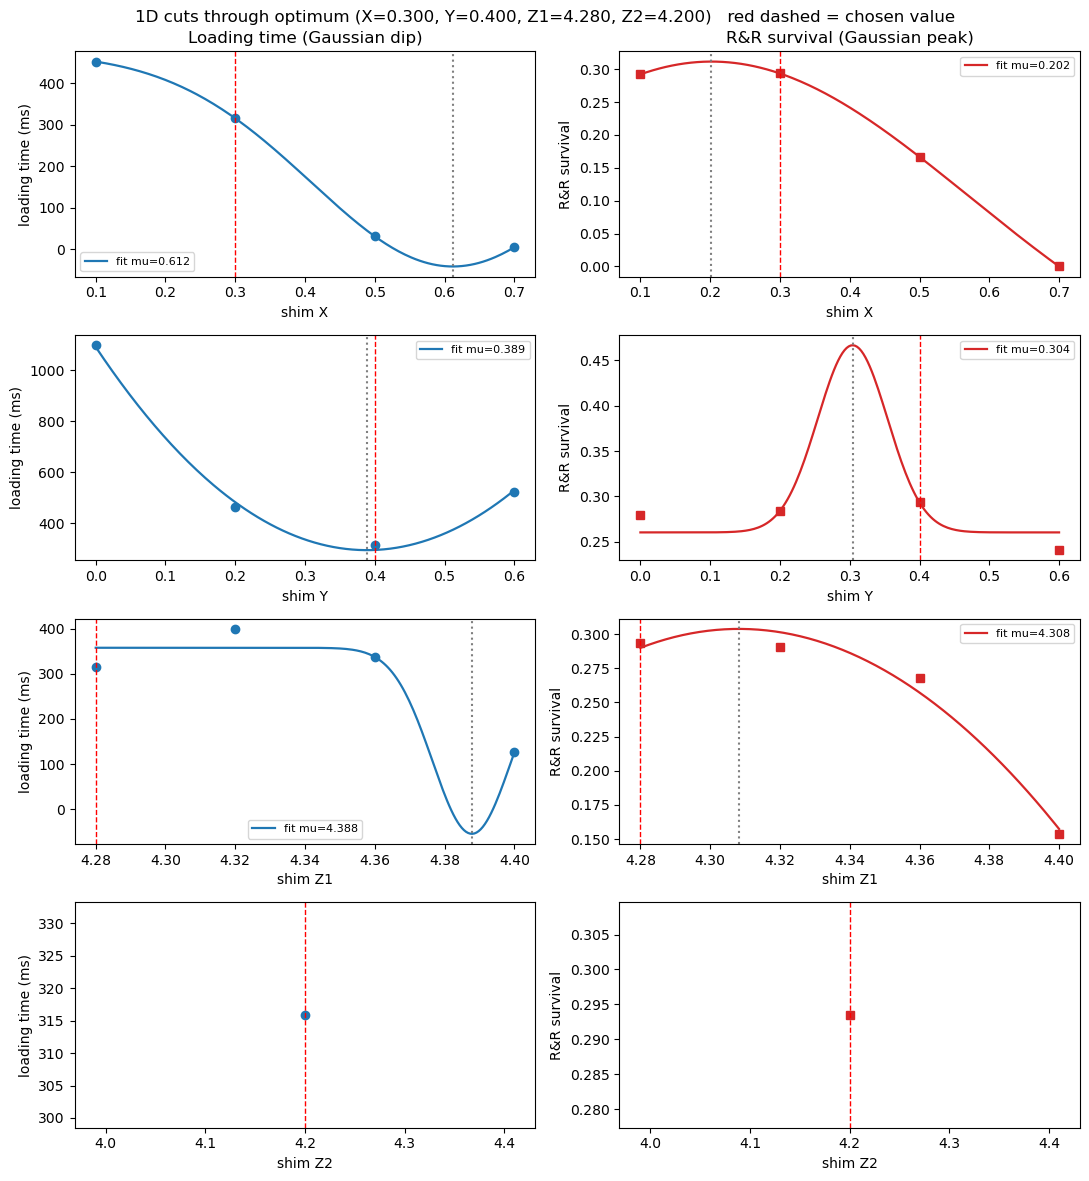

In [108]:
########################################
CASE = 1   # 1 = fastest, 2 = best R&R survival, 3 = both
########################################

center = pick_case(rec, CASE)
if center is None:
    print("No optimum: no point passed the loading gate (see cell 5).")
else:
    print(f"CASE {CASE} chosen scan values:")
    print(f"  shim_X_compression  = {center['X']:.3f}")
    print(f"  shim_Y_compression  = {center['Y']:.3f}")
    print(f"  shim_Z1_compression = {center['Z1']:.3f}")
    print(f"  shim_Z2_compression = {center['Z2']:.3f}")
    print(f"  grades: time={center['grade_time']:.0f}/100  survival={center['grade_survival']:.0f}/100  both={center['grade_both']:.0f}/200")
    plot_axis_gaussians(agg, center)